In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/archive (6).zip')
print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   


In [4]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)
print("\nDataset Information:")
df.info()

Dataset Shape: (8807, 12)

Column Names:
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

Data Types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added

In [5]:
print("\nLast 5 Rows:")
print(df.tail())


Last 5 Rows:
     show_id     type        title         director  \
8802   s8803    Movie       Zodiac    David Fincher   
8803   s8804  TV Show  Zombie Dumb              NaN   
8804   s8805    Movie   Zombieland  Ruben Fleischer   
8805   s8806    Movie         Zoom     Peter Hewitt   
8806   s8807    Movie       Zubaan      Mozez Singh   

                                                   cast        country  \
8802  Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...  United States   
8803                                                NaN            NaN   
8804  Jesse Eisenberg, Woody Harrelson, Emma Stone, ...  United States   
8805  Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...  United States   
8806  Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...          India   

             date_added  release_year rating   duration  \
8802  November 20, 2019          2007      R    158 min   
8803       July 1, 2019          2018  TV-Y7  2 Seasons   
8804   November 1, 2019          

In [6]:
missing = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing)

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [7]:
missing_percent = (df.isnull().sum() / len(df)) * 100
print("Missing Value Percentage:")
print(missing_percent)

Missing Value Percentage:
show_id          0.000000
type             0.000000
title            0.000000
director        29.908028
cast             9.367549
country          9.435676
date_added       0.113546
release_year     0.000000
rating           0.045418
duration         0.034064
listed_in        0.000000
description      0.000000
dtype: float64


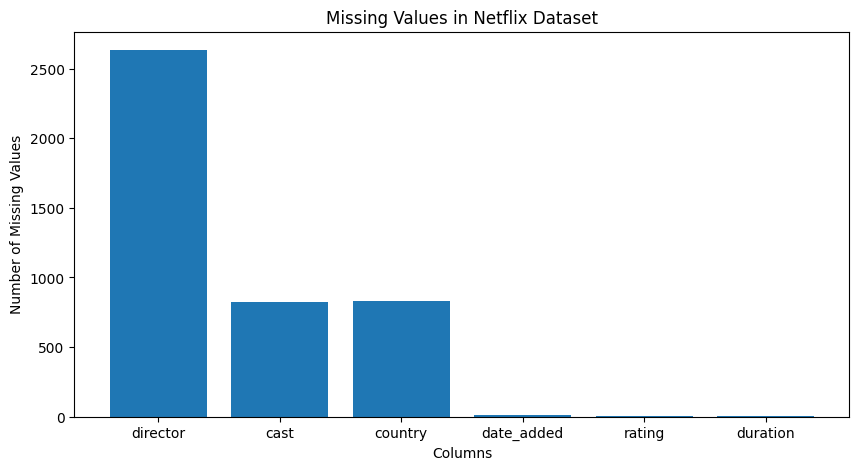

'The bar chart shows the number of missing values in each column. Some columns contain more missing values than others. These missing values should be handled carefully before performing further data analysis.'

In [20]:
plt.figure(figsize=(10,5))
missing = df.isnull().sum()
missing = missing[missing > 0]
plt.bar(missing.index, missing.values)
plt.title("Missing Values in Netflix Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.show()
"The bar chart shows the number of missing values in each column. Some columns contain more missing values than others. These missing values should be handled carefully before performing further data analysis."

In [10]:
print(df.describe())

       release_year
count   8807.000000
mean    2014.180198
std        8.819312
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000


In [12]:
print(df['type'].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


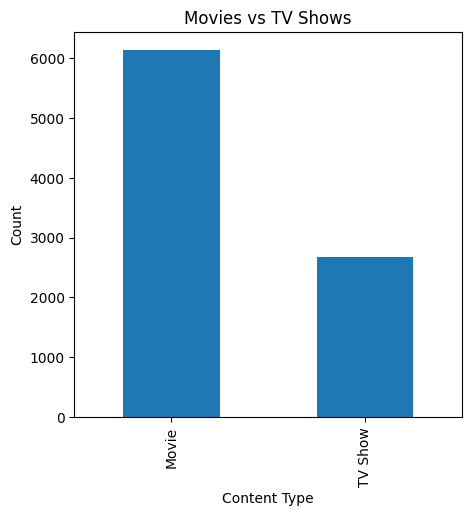

'The bar chart compares the number of Movies and TV Shows available on Netflix. It helps identify which content type is more common in the dataset.'

In [18]:
plt.figure(figsize=(5,5))
df['type'].value_counts().plot(kind='bar')
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()
"The bar chart compares the number of Movies and TV Shows available on Netflix. It helps identify which content type is more common in the dataset."

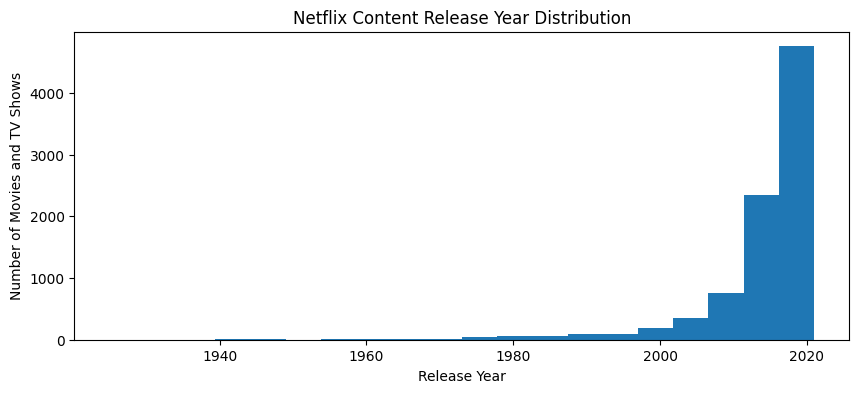

In [29]:
plt.figure(figsize=(10,4))
plt.hist(df['release_year'], bins=20)
plt.title("Netflix Content Release Year Distribution")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies and TV Shows")
plt.show()

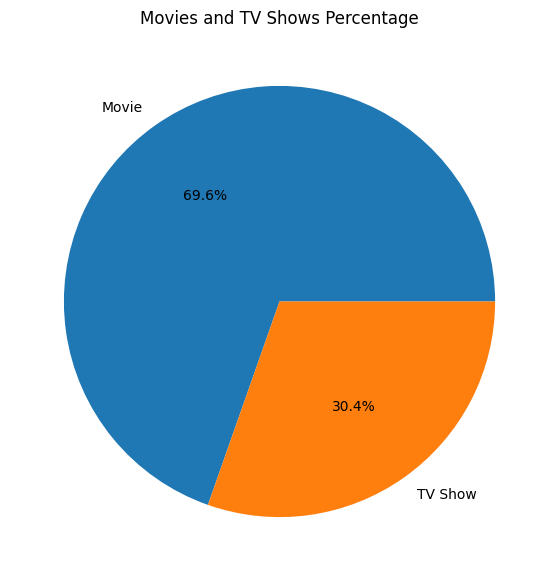

In [30]:
plt.figure(figsize=(7,7))
df['type'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Movies and TV Shows Percentage")
plt.ylabel("")
plt.show()

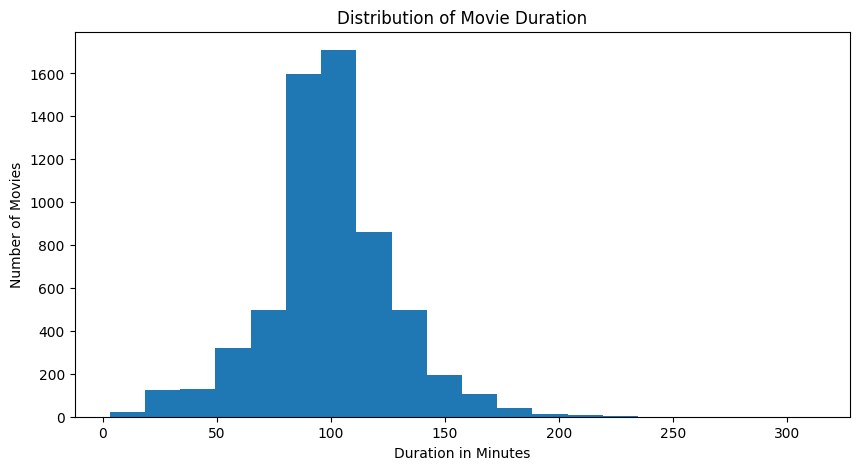

In [31]:
movie = df[df['type'] == 'Movie'].copy()
duration = pd.to_numeric(
    movie['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
).dropna()
plt.figure(figsize=(10,5))
plt.hist(duration, bins=20)
plt.title("Distribution of Movie Duration")
plt.xlabel("Duration in Minutes")
plt.ylabel("Number of Movies")
plt.show()

In [ ]:
# Final Findings

Based on the Exploratory Data Analysis of the Netflix dataset, the following findings were identified:

1. Content Distribution: Movies are more common than TV Shows in the Netflix dataset.

2. Missing Values: Several columns contain missing values, especially Director, Cast, and Country.

3. Content Release Trends: The release year analysis shows variations in Netflix content releases over different years.

4. Movie Duration: Movie duration analysis helps understand the distribution of movie lengths.

# Conclusion

This EDA project helped me understand the Netflix dataset using Python, Pandas, Matplotlib, and Seaborn. I analysed missing values, summary statistics, categorical data, and visual patterns to gain useful insights from the dataset.